I still need to calculate the decorrelation scale in order to correctly conduct the interpolation. To do this, I need to calculate the correlation between the yearly DO time series data. But there are some missing values in the data frame that I'm using for the correlation analysis. So I need to do a spatial interpolation first on this data frame to fill in the missing values. But to do the spatial interpolation using weighted average, I need the decorrelation value as a part of the equation. So which one do I need to do first?

Solution: I don't need a complete time-series data to conduct the correlation-distance analysis. 

In [2]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy.interpolate import griddata
import matplotlib.cm as cm
import matplotlib.colors as colors
import imageio
import glob
import skgstat as skg
from scipy.spatial.distance import cdist
from scipy.optimize import curve_fit

In [3]:
# In [2]: Load and Prepare Data
# Load the pre-processed data
merged_gdf = pd.read_feather('../data/processed/merged_gdf.feather', use_threads=False)
merged_gdf = gpd.GeoDataFrame(merged_gdf, geometry=gpd.points_from_xy(merged_gdf.longitude, merged_gdf.latitude), crs='EPSG:4326')

# Filter summer bottom do data
summer_bottom_df = merged_gdf[
    (merged_gdf['season'] == 'Summer') &
    (merged_gdf['saisuipoin'] == 2)
].dropna(subset=['do_']).copy()

print(summer_bottom_df.head())

      uniqueid zettaicode locationna wancode prefectuei  watercode renban  \
4   0000001734   00002811      兵庫県11      03         28        301     11   
12  0000001742   00002823      兵庫県23      03         28        301     23   
19  0000001678   00000272       大阪府2      03         27        301      2   
27  0000001686   00000275       大阪府5      03         27        301      5   
35  0000001694   00002725      大阪府25      03         27        301     25   

    nendo  survey_ym  surveyyear  ...   doc  doc2  dataflag  scale  \
4    1981 1981-06-01        1981  ...  None   0.0         1     -1   
12   1981 1981-06-01        1981  ...  None   0.0         1     -1   
19   1981 1981-06-01        1981  ...  None   0.0         1     -1   
27   1981 1981-06-01        1981  ...  None   0.0         1     -1   
35   1981 1981-06-01        1981  ...  None   0.0         1     -1   

                      geometry  year   watermass_name   division  \
4     POINT (135.33056 34.695)  1981  Seto Inlan

In [4]:
# Create dictionary grouped by 'zettaicode'
# For each group, select 'year' and 'do_', then set 'year' as the index
points_dict = {name: group[['year', 'do_']].set_index('year')
    for name, group in summer_bottom_df.groupby('zettaicode')}

In [5]:
# combine all of the points dataframes into a single dataframe, with the index as 'zettaicode' and columns as years
yearly_do = []
for zettaicode, df in points_dict.items():
    numeric_index = pd.to_numeric(df.index, errors='coerce')    
    series = df['do_'].groupby(numeric_index).mean().rename(zettaicode)
    yearly_do.append(series)

yearly_do_df = pd.concat(yearly_do, axis=1).T

In [6]:
import sys
import os

# Add the project root to sys.path to allow importing from scripts
# This assumes the notebook is running from the 'notebooks' directory
project_root = os.path.abspath('..')
if project_root not in sys.path:
    sys.path.append(project_root)

from scripts.export_csv import save_to_processed

save_to_processed(yearly_do_df, "yearly_do_df")

Successfully saved to: C:\Users\reyha\Documents\SIS_Analysis\data\processed\yearly_do_df.csv


In [7]:
# Diagnostic: understand the DataFrame structure
print("DataFrame shape:", yearly_do_df.shape)
print("\nColumn names:")
print(yearly_do_df.columns.tolist())
print("\nFirst few rows:")
print(yearly_do_df.head())
print("\nData types:")
print(yearly_do_df.dtypes)
print("\nIndex:")
print(yearly_do_df.index)

DataFrame shape: (127, 42)

Column names:
[1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2016, 2017, 2018, 2019, 2020, 2021, 2015, 2014, 2022]

First few rows:
year      1981  1982  1983  1984  1985  1986  1987  1988  1989  1990  ...  \
00000272   2.6   4.0   1.5   1.1   1.9   2.1   0.8   2.9   2.1   1.5  ...   
00000275   3.7   1.1   NaN   1.5   0.7   3.1   NaN   1.1   1.4   0.3  ...   
00002725   7.9   5.6   5.4   4.8   3.9   9.5   6.2   5.0   5.5   5.9  ...   
00002737   8.3   6.8   5.6   5.4   5.1   6.6   6.0   4.7   6.0   4.6  ...   
00002744   7.7   6.6   6.8   3.6   4.8   5.8   5.8   5.5   5.6   6.4  ...   

year      2013  2016  2017  2018  2019  2020  2021  2015  2014  2022  
00000272   1.7   0.6   0.7   1.1   1.1   0.8   1.1   NaN   NaN   NaN  
00000275   0.5   NaN   NaN   0.6   0.8   2.3   0.6   0.6   NaN   NaN  
00002725   5

In [8]:
# Use .loc to access a row by its index label (the zettaicode)
point1 = yearly_do_df.loc['00002725']
point2 = yearly_do_df.loc['00002823'] 
point3 = yearly_do_df.loc['00000272']
point4 = yearly_do_df.loc['00000275']

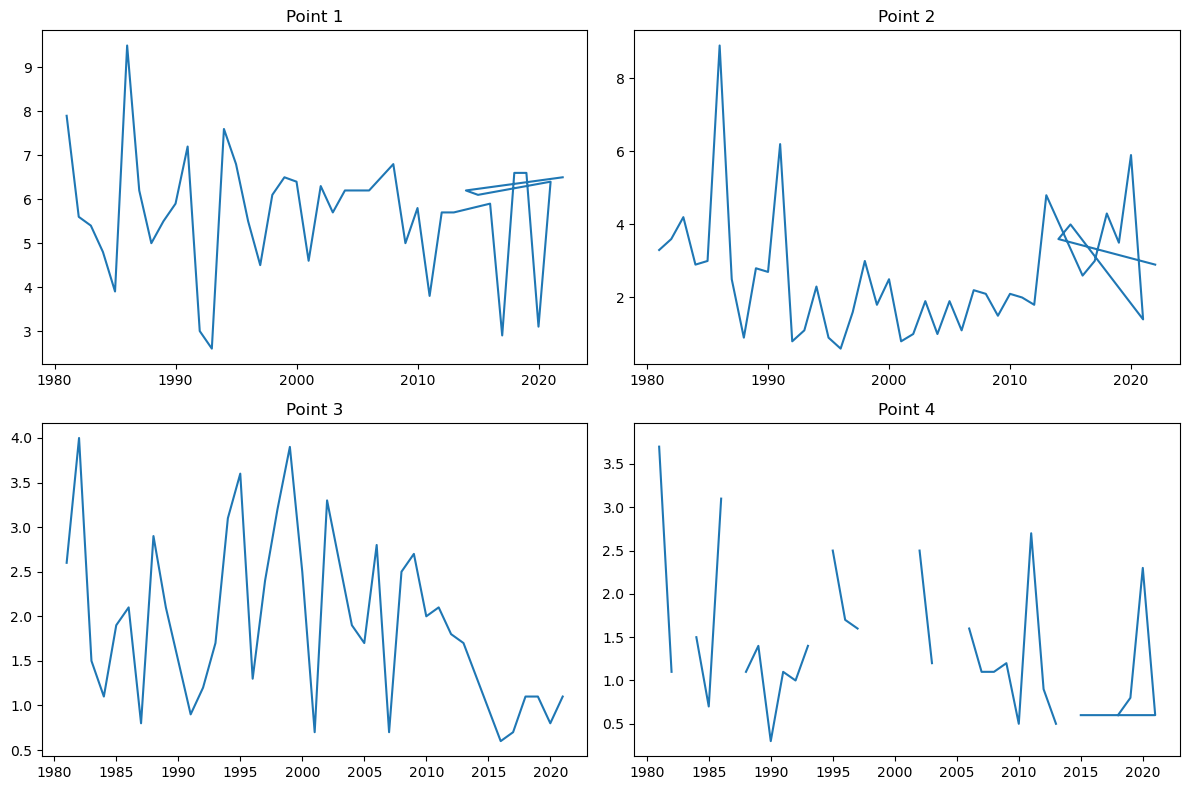

In [9]:
# plot 4 points in a 2x2 grid subplot
fig, axs = plt.subplots(2, 2, figsize=(12, 8))
axs[0, 0].plot(point1)
axs[0, 0].set_title('Point 1')

axs[0, 1].plot(point2)
axs[0, 1].set_title('Point 2')

axs[1, 0].plot(point3)
axs[1, 0].set_title('Point 3')

axs[1, 1].plot(point4)
axs[1, 1].set_title('Point 4')

plt.tight_layout()
plt.show()

Let's try to conduct correlation analysis of each of these sampling points based on the summer bottom data. It's ok to not have the complete time series data for all of the points. Just do the correlation analysis with the currently available data. Then, plot the correlation against distance.

In [10]:
# Calculate the correlation matrix
# Transpose so that the columns are stations, min period = 10 to include pairs that shares at least 10 years of data
corr_matrix = yearly_do_df.T.corr(method='pearson', min_periods=10)

# Calculate the distance matrix
station_locs = summer_bottom_df.drop_duplicates('zettaicode').set_index('zettaicode')
station_locs = station_locs.loc[yearly_do_df.index]  # Ensure exact ordering matches the corr_matrix

# project to a metric CRS to calculate the distance in kilometers
station_locs_proj = station_locs.to_crs(epsg=32653)

# Create an array of (x, y) coordinates
coords = list(zip(station_locs_proj.geometry.x, station_locs_proj.geometry.y))

# Calculate Euclidean distance matrix (result is in meters, so divide by 1000 for km)
dist_matrix_m = cdist(coords, coords, metric='euclidean')
dist_matrix_km = pd.DataFrame(
    dist_matrix_m / 1000,
    index=yearly_do_df.index,
    columns=yearly_do_df.index
)

This chunk calculates the correlation matrix from the yearly DO data. Then it calculates the distance matrix between each of the unique sampling points, both in meter and kilometer. 

In [11]:
display(dist_matrix_km.describe().T)

,count,mean,std,min,25%,50%,75%,max
00000272,127.0,233.593809,124.092786,0.0,104.969048,261.250582,340.152334,430.230476
00000275,127.0,230.903082,124.062285,0.0,102.308587,259.296413,336.810746,428.944309
00002725,127.0,218.804989,122.698845,0.0,89.367244,246.104908,324.024191,415.689783
00002737,127.0,210.531612,120.363529,0.0,83.682151,237.471252,313.836502,407.770340
00002744,127.0,206.172507,120.014215,0.0,77.460725,232.301530,309.020281,402.377453
...,...,...,...,...,...,...,...,...
00044679,127.0,163.630621,93.756861,0.0,94.904965,142.598025,251.691781,352.954897
00044680,127.0,172.528013,92.862337,0.0,106.246868,153.144381,258.934454,359.470247
00044690,127.0,152.683944,98.969359,0.0,70.302145,127.554401,249.451727,352.113688
00044696,127.0,174.524131,98.020267,0.0,102.070168,151.920151,268.128908,369.419905


In [12]:
# save the distance matrix to csv
save_to_processed(dist_matrix_km, "dist_matrix_km")

Successfully saved to: C:\Users\reyha\Documents\SIS_Analysis\data\processed\dist_matrix_km.csv


Prompt: Write me a code to make a new dataframe containing a list of unique distance values from the dist_matrix_km. The first column is the distance value sorted by ascending order, and the second column is the count of how many times that distance value appears in the dist_matrix_km. 

In [13]:
# Count occurrences of each distance
unique_distances, counts = np.unique(dist_matrix_km, return_counts=True)
dist_counts_df = pd.DataFrame({
    'distance': unique_distances,
    'count': counts
})

save_to_processed(dist_counts_df, 'dist_counts.csv')

Error saving file: [Errno 13] Permission denied: 'C:\\Users\\reyha\\Documents\\SIS_Analysis\\data\\processed\\dist_counts.csv'


In [14]:
# calculate and print the mean of dist_counts_df['distance']
print(dist_counts_df['distance'].mean())


155.283334424496


In [15]:
# Flatten and Merge for plotting
# We only need the upper triangle of the matrix to avoid duplicates
mask = np.triu(np.ones(corr_matrix.shape), k=1).astype(bool) # Create a boolean mask for the upper triangle

# Flatten correlation matrix
corr_flat = corr_matrix.where(mask).stack().reset_index()
corr_flat.columns = ['Point_A', 'Point_B', 'Correlation']

# Flatten Distance Matrix
dist_flat = dist_matrix_km.where(mask).stack().reset_index()
dist_flat.columns = ['Point_A', 'Point_B', 'Distance_km']

# Combine them into a single analysis DataFrame
decorrelation_df = pd.merge(corr_flat, dist_flat, on=['Point_A', 'Point_B'])

In [16]:
print(decorrelation_df.shape)
print(decorrelation_df.nunique())
display(decorrelation_df.describe().T)

(7995, 4)
Point_A         126
Point_B         126
Correlation    7995
Distance_km    7995
dtype: int64


,count,mean,std,min,25%,50%,75%,max
Correlation,7995.0,0.050116,0.214649,-0.858029,-0.094566,0.038051,0.183297,0.973088
Distance_km,7995.0,155.203443,97.653736,0.806721,74.346909,135.516319,228.479492,430.230476


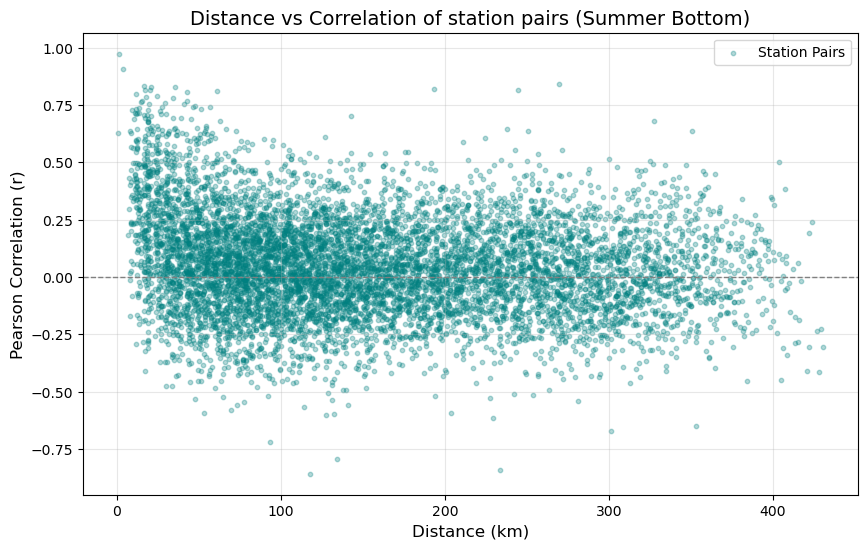

In [17]:
# Plotting the graph

fig, ax = plt.subplots(figsize=(10, 6))

plt.scatter(
    decorrelation_df['Distance_km'],
    decorrelation_df['Correlation'],
    alpha=0.3,
    s=10,
    c='teal',
    label='Station Pairs'
)

# add zero correlation line
plt. axhline(0, color='grey', linestyle='--', linewidth=1)

# formatting
plt.title('Distance vs Correlation of station pairs (Summer Bottom)', fontsize=14)
plt.xlabel('Distance (km)', fontsize=12)
plt.ylabel('Pearson Correlation (r)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

This result shows a pattern that is close to what I'm expecting. Which is that the further two points are away from each other, the less correlated they are. However, the distribution doesn't perfectly match . Let's use gaussian curve-fitting to test this.

--- Fitting Results ---
Intercept (A): 0.2975
Decorrelation Scale (e-folding): 45.7548 km


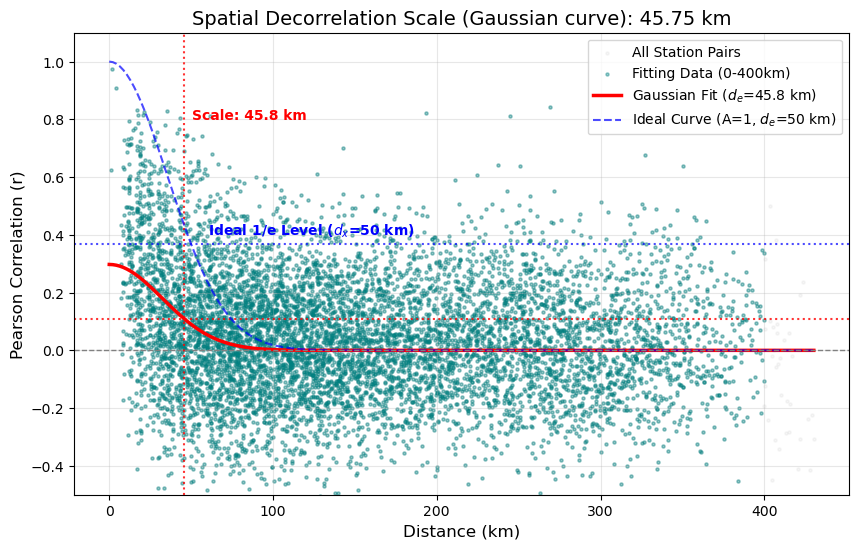

In [18]:
# === 1. Define the Gaussian Model ===
def gaussian_correlation(x, A, dx):
    """
    x: Distance (lag)
    A: Intercept (theoretical correlation at distance 0)
    dx: Decorrelation scale (e-folding scale)
    """
    return A * np.exp(-(x / dx)**2)

# === 2. Prepare Data for Fitting ===
# Based on the methodology of that other paper
FIT_LIMIT_KM = 400

# Filter the dataframe to valid pairs within the limit
df_fit = decorrelation_df[
    (decorrelation_df['Distance_km'] <= FIT_LIMIT_KM) & 
    (decorrelation_df['Correlation'].notna())
].copy()

# Sort by distance (helper for plotting lines later)
df_fit = df_fit.sort_values('Distance_km')

# Data for fitting
x_data = df_fit['Distance_km'].values
y_data = df_fit['Correlation'].values

# === 3. Fit the Model ===
# Initial guesses (p0):
# A = 1.0 (perfect correlation at 0 distance)
# dx = 50.0 (start guess for scale)
popt, pcov = curve_fit(gaussian_correlation, x_data, y_data, p0=[1.0, 50.0])

A_fit, dx_fit = popt

print("--- Fitting Results ---")
print(f"Intercept (A): {A_fit:.4f}")
print(f"Decorrelation Scale (e-folding): {dx_fit:.4f} km")

# === 4. Visualization ===
if dx_fit is not None:
    fig, ax = plt.subplots(figsize=(10, 6))

    # A. Plot the raw scatter (background noise)
    # Plotting ALL data (even beyond 150km) in grey to show context
    plt.scatter(
        decorrelation_df['Distance_km'], 
        decorrelation_df['Correlation'], 
        alpha=0.2, s=5, color='lightgrey', label='All Station Pairs'
    )

    # B. Highlight the data used for fitting (0-150km)
    plt.scatter(
        x_data, y_data, 
        alpha=0.4, s=5, color='teal', label=f'Fitting Data (0-{FIT_LIMIT_KM}km)'
    )

    # C. Plot the Fitted Gaussian Curve
    # Generate smooth x axis for the line
    x_line = np.linspace(0, decorrelation_df['Distance_km'].max(), 200)
    y_line = gaussian_correlation(x_line, A_fit, dx_fit)
    
    plt.plot(x_line, y_line, 'r-', linewidth=2.5, label=f'Gaussian Fit ($d_e$={dx_fit:.1f} km)')

    # D. Add visual markers for the scale
    plt.axvline(dx_fit, color='red', linestyle=':', alpha=0.8)
    plt.axhline(A_fit * 0.37, color='red', linestyle=':', alpha=0.8) # 1/e level approx 0.37
    plt.text(dx_fit + 5, 0.8, f'Scale: {dx_fit:.1f} km', color='red', fontweight='bold')

    # E. Plot the hypothethical ideal curve for A=1 and dx=50 (light blue dashed line)
    y_ideal = gaussian_correlation(x_line, 1.0, 50.0)
    plt.plot(x_line, y_ideal, color='b', linestyle='--', linewidth=1.5, alpha=0.7, label='Ideal Curve (A=1, $d_e$=50 km)')
    plt.axhline(1.0 * 0.37, color='b', linestyle=':', alpha=0.7)
    plt.text(60, 0.4, 'Ideal 1/e Level ($d_x$=50 km)', color='b', fontweight='bold')
    
    # Formatting
    plt.title(f'Spatial Decorrelation Scale (Gaussian curve): {dx_fit:.2f} km', fontsize=14)
    plt.xlabel('Distance (km)', fontsize=12)
    plt.ylabel('Pearson Correlation (r)', fontsize=12)
    plt.axhline(0, color='grey', linestyle='--', linewidth=1)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.ylim(-0.5, 1.1) # Constrain y-axis to relevant range
    
    plt.show()

This result suggest that the correlation is not restricted to the distance of station points. This means that two different places that are far apart in space can still show similar pattern if they have similar environmental characteristics, which leads to the same phenomenon. For example, Hiroshima Bay and Tokyo Bay might show similar pattern because of the high nutrition load, even though they are located very far appart from each other.

--- Fitting Results ---
Intercept (A): 0.4626
Decorrelation Scale: 30.9627 km


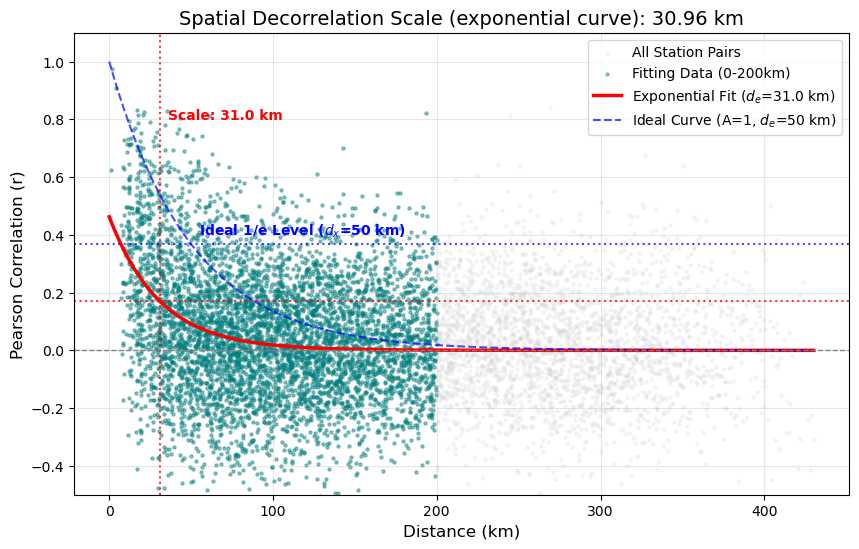

In [19]:
# New approach with Exponential Decay Model
# === 1. Define the model ===
def exponential_decay(x, A, dx):
    """
    x: Distance (lag)
    A: Intercept (theoretical correlation at distance 0)
    dx: Decorrelation scale (exponential decay)
    """
    return A * np.exp(-(x / dx)) # changed to exponential decay curve (not squared)

# === 2. Prepare Data for Fitting ===
FIT_LIMIT_KM = 200

# Filter the dataframe to valid pairs within the limit
df_fit = decorrelation_df[
    (decorrelation_df['Distance_km'] <= FIT_LIMIT_KM) & 
    (decorrelation_df['Correlation'].notna())
].copy()

# Sort by distance (helper for plotting lines later)
df_fit = df_fit.sort_values('Distance_km')

# Data for fitting
x_data = df_fit['Distance_km'].values
y_data = df_fit['Correlation'].values

# === 3. Fit the Model ===
popt, pcov = curve_fit(exponential_decay, x_data, y_data, p0=[1.0, 50.0])

A_fit, dx_fit = popt

print("--- Fitting Results ---")
print(f"Intercept (A): {A_fit:.4f}")
print(f"Decorrelation Scale: {dx_fit:.4f} km")

# === 4. Visualization ===
if dx_fit is not None:
    fig, ax = plt.subplots(figsize=(10, 6))

    # A. Plot the raw scatter (background noise)
    # Plotting ALL data (even beyond 150km) in grey to show context
    plt.scatter(
        decorrelation_df['Distance_km'], 
        decorrelation_df['Correlation'], 
        alpha=0.2, s=5, color='lightgrey', label='All Station Pairs'
    )

    # B. Highlight the data used for fitting (0-150km)
    plt.scatter(
        x_data, y_data, 
        alpha=0.4, s=5, color='teal', label=f'Fitting Data (0-{FIT_LIMIT_KM}km)'
    )

    # C. Plot the Fitted Curve
    # Generate smooth x axis for the line
    x_line = np.linspace(0, decorrelation_df['Distance_km'].max(), 200)
    y_line = exponential_decay(x_line, A_fit, dx_fit)
    
    plt.plot(x_line, y_line, 'r-', linewidth=2.5, label=f'Exponential Fit ($d_e$={dx_fit:.1f} km)')

    # D. Add visual markers for the scale
    plt.axvline(dx_fit, color='red', linestyle=':', alpha=0.8)
    plt.axhline(A_fit * 0.37, color='red', linestyle=':', alpha=0.8) # 1/e level approx 0.37
    plt.text(dx_fit + 5, 0.8, f'Scale: {dx_fit:.1f} km', color='red', fontweight='bold')

    # E. Plot the hypothethical ideal curve for A=1 and dx=50 (light blue dashed line)
    y_ideal = exponential_decay(x_line, 1.0, 50.0)
    plt.plot(x_line, y_ideal, color='b', linestyle='--', linewidth=1.5, alpha=0.7, label='Ideal Curve (A=1, $d_e$=50 km)')
    # plot the 1/e line for the ideal curve
    plt.axhline(1.0 * 0.37, color='b', linestyle=':', alpha=0.7)
    plt.text(55, 0.4, 'Ideal 1/e Level ($d_x$=50 km)', color='b', fontweight='bold')
    
    # Formatting
    plt.title(f'Spatial Decorrelation Scale (exponential curve): {dx_fit:.2f} km', fontsize=14)
    plt.xlabel('Distance (km)', fontsize=12)
    plt.ylabel('Pearson Correlation (r)', fontsize=12)
    plt.axhline(0, color='grey', linestyle='--', linewidth=1)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.ylim(-0.5, 1.1) # Constrain y-axis to relevant range
    
    plt.show()

Using a 200 km fit limit, the decorrelation scale is 167.7 km for the gaussian curve fitting and 113 km for the exponential curve fitting. I still don't trust these results because the resulting decorrelation scale still heavily depends on the distance I choose for the fit limit. And I don't have any concrete basis for the distance I should choose for this limit.